# Semana 9 — backbone, CBAM y detección 2.5D conectados con Semana 10

Este notebook es la nueva propuesta de Semana 9. Entrena únicamente los componentes exigidos en esa semana:

```text
[Z-1, Z, Z+1] → FundidoraBackbone → CBAM → cabeza de detección
```

Su checkpoint es la entrada obligatoria del notebook `10_semana10_multitarea_desde_semana9_25d.ipynb`. Semana 10 no vuelve a ejecutar este entrenamiento: carga sus pesos y agrega las cabezas nuevas.

In [1]:
import os
import sys
import json
import time
import subprocess
from pathlib import Path

def encontrar_raiz(inicio: Path) -> Path:
    for candidato in (inicio, *inicio.parents):
        if (candidato / "src" / "train_week9_detection.py").exists() and (candidato / "README.md").exists():
            return candidato
    raise FileNotFoundError("No encontré la raíz del repositorio.")

ROOT = encontrar_raiz(Path.cwd().resolve())
os.chdir(ROOT)
os.environ["PYTHONUTF8"] = "1"
print("Raíz:", ROOT)
print("Python:", sys.version.split()[0], "| ejecutable:", sys.executable)

Raíz: E:\Proyecto_2_Analytics\proyecto2-analitica-datos-main
Python: 3.12.6 | ejecutable: e:\Proyecto_2_Analytics\proyecto2-analitica-datos-main\.venv\Scripts\python.exe


## 1. Configuración

Ejecuta primero el modo rápido en ambos notebooks. Cuando funcione, cambia `MODO_RAPIDO=False` también en ambos para la corrida completa.

In [2]:
MODO_RAPIDO = False
EXIGIR_GPU = True
PREPARAR_CACHE = True
RECONSTRUIR_CACHE = False
EJECUTAR_ENTRENAMIENTO = True

CONTEXT = 1
SIZE = 384
SEED = 42
SALIDA_DIR = ROOT / "outputs" / "week9_25d"
SALIDA_DIR.mkdir(parents=True, exist_ok=True)

if MODO_RAPIDO:
    NOMBRE = "smoke_week9_25d_cbam_w8_e2_s42"
    CACHE = ROOT / "data" / "cache" / "week9_detection_25d_smoke_384.npz"
    EPOCHS, BASE_CHANNELS, BATCH_SIZE = 2, 8, 4
    TRAIN_CASES, VAL_CASES = 4, 2
    SLICES_PER_CASE, NEGATIVES_PER_CASE = 2, 1
else:
    NOMBRE = "week9_25d_cbam_w32_e35_s42"
    CACHE = ROOT / "data" / "cache" / "week9_detection_25d_384.npz"
    EPOCHS, BASE_CHANNELS, BATCH_SIZE = 35, 32, 4
    TRAIN_CASES, VAL_CASES = 70, 15
    SLICES_PER_CASE, NEGATIVES_PER_CASE = 12, 2

CHECKPOINT = SALIDA_DIR / f"{NOMBRE}.pth"
HISTORIAL = CHECKPOINT.with_suffix(".json")
LOG = SALIDA_DIR / f"{NOMBRE}_train.log"
print("Modo:", "RÁPIDO" if MODO_RAPIDO else "COMPLETO")
print("Caché:", CACHE)
print("Checkpoint que consumirá Semana 10:", CHECKPOINT)

Modo: COMPLETO
Caché: E:\Proyecto_2_Analytics\proyecto2-analitica-datos-main\data\cache\week9_detection_25d_384.npz
Checkpoint que consumirá Semana 10: E:\Proyecto_2_Analytics\proyecto2-analitica-datos-main\outputs\week9_25d\week9_25d_cbam_w32_e35_s42.pth


In [3]:
import torch
print("PyTorch:", torch.__version__)
print("CUDA disponible:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("Memoria GPU: %.1f GB" % (torch.cuda.get_device_properties(0).total_memory / 1024**3))
elif EXIGIR_GPU:
    raise RuntimeError("No hay GPU CUDA. Selecciona el kernel del entorno .venv con PyTorch CUDA.")

PyTorch: 2.11.0+cu128
CUDA disponible: True
GPU: NVIDIA GeForce GTX 1650 SUPER
Memoria GPU: 4.0 GB


In [4]:
def ejecutar_visible(comando, titulo, log_path=None):
    print(f"\n=== {titulo} ===")
    print(" ".join(map(str, comando)))
    inicio = time.time()
    with subprocess.Popen(comando, cwd=ROOT, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                          text=True, encoding="utf-8", errors="replace", bufsize=1) as proceso:
        lineas = []
        for linea in proceso.stdout:
            print(linea, end="")
            lineas.append(linea)
        codigo = proceso.wait()
    if log_path is not None:
        log_path.write_text("".join(lineas), encoding="utf-8")
    print(f"=== finalizó con código {codigo} en {(time.time()-inicio)/60:.1f} min ===")
    if codigo != 0:
        raise RuntimeError(f"El comando terminó con código {codigo}.")

## 2. Preparar el caché 2.5D

Los tres canales se construyen antes del entrenamiento y usan la misma orientación canónica de Semana 10. El target siempre corresponde al corte central `Z`.

In [5]:
comando_cache = [
    sys.executable, "src/prepare_week9_detection_data.py",
    "--output", str(CACHE), "--size", str(SIZE),
    "--context", str(CONTEXT), "--canonical",
    "--slices-per-case", str(SLICES_PER_CASE),
    "--negatives-per-case", str(NEGATIVES_PER_CASE),
    "--max-train-cases", str(TRAIN_CASES), "--max-val-cases", str(VAL_CASES),
    "--extent", "0.0", "1.0",
]
if RECONSTRUIR_CACHE and CACHE.exists():
    CACHE.unlink()
if PREPARAR_CACHE and not CACHE.exists():
    ejecutar_visible(comando_cache, "Preparación caché Semana 9 2.5D")
elif CACHE.exists():
    print("Se reutiliza el caché:", CACHE)
else:
    raise FileNotFoundError("No existe el caché y PREPARAR_CACHE=False.")


=== Preparación caché Semana 9 2.5D ===
e:\Proyecto_2_Analytics\proyecto2-analitica-datos-main\.venv\Scripts\python.exe src/prepare_week9_detection_data.py --output E:\Proyecto_2_Analytics\proyecto2-analitica-datos-main\data\cache\week9_detection_25d_384.npz --size 384 --context 1 --canonical --slices-per-case 12 --negatives-per-case 2 --max-train-cases 70 --max-val-cases 15 --extent 0.0 1.0

Preparando train: 100%|██████████| 70/70 [04:23<00:00,  3.76s/it]

Preparando val: 100%|██████████| 15/15 [00:43<00:00,  2.93s/it]

Preparando test: 0it [00:00, ?it/s]
Preparando test: 0it [00:00, ?it/s]
Cache: E:\Proyecto_2_Analytics\proyecto2-analitica-datos-main\data\cache\week9_detection_25d_384.npz | gamma=1.5 | context=1 | canonical=True | cortes=1190 | train=980 | val=210 | test=0
=== finalizó con código 0 en 5.7 min ===


In [6]:
import numpy as np
with np.load(CACHE) as datos:
    print("images:", datos["images"].shape)
    print("labels:", datos["labels"].shape)
    print("context:", int(datos["context"]))
    print("canonical:", bool(datos["canonical"]))
    assert datos["images"].shape[1] == 3
    assert int(datos["context"]) == 1
    assert bool(datos["canonical"])
print("OK: entrada Semana 9 = [Z-1, Z, Z+1].")

images: (1190, 3, 384, 384)
labels: (1190, 384, 384)
context: 1
canonical: True
OK: entrada Semana 9 = [Z-1, Z, Z+1].


## 3. Entrenar backbone, CBAM y detector

In [7]:
comando_entrenamiento = [
    sys.executable, "src/train_week9_detection.py",
    "--cache", str(CACHE), "--epochs", str(EPOCHS),
    "--batch-size", str(BATCH_SIZE), "--base-channels", str(BASE_CHANNELS),
    "--cbam-stages", "1", "--seed", str(SEED),
    "--disable-cudnn", "--output", str(CHECKPOINT),
]
if EJECUTAR_ENTRENAMIENTO:
    ejecutar_visible(comando_entrenamiento, "Entrenamiento Semana 9 2.5D", LOG)
elif CHECKPOINT.exists():
    print("Se reutiliza:", CHECKPOINT)
else:
    raise FileNotFoundError("No existe el checkpoint y EJECUTAR_ENTRENAMIENTO=False.")


=== Entrenamiento Semana 9 2.5D ===
e:\Proyecto_2_Analytics\proyecto2-analitica-datos-main\.venv\Scripts\python.exe src/train_week9_detection.py --cache E:\Proyecto_2_Analytics\proyecto2-analitica-datos-main\data\cache\week9_detection_25d_384.npz --epochs 35 --batch-size 4 --base-channels 32 --cbam-stages 1 --seed 42 --disable-cudnn --output E:\Proyecto_2_Analytics\proyecto2-analitica-datos-main\outputs\week9_25d\week9_25d_cbam_w32_e35_s42.pth
Codificacion del target: 0 regiones reubicadas por colision de celda, 0 descartadas
Modelo: 32 canales base, CBAM si, 1 etapas
Entrada: context=1, canales=3, canonical=True, tamaño=(384, 384)
Dispositivo: cuda | precisión mixta=True | cuDNN=False

epoch 001 train_loss=0.7925 F1=0.000 P=0.000 R=0.000 FP=34 iou=0.006  <- mejor
epoch 002 train_loss=0.4016 F1=0.068 P=0.057 R=0.084 FP=609 iou=0.153  <- mejor
epoch 003 train_loss=0.3676 F1=0.111 P=0.080 R=0.177 FP=893 iou=0.200  <- mejor
epoch 005 train_loss=0.2320 F1=0.187 P=0.186 R=0.189 FP=364 iou=

## 4. Verificar el artefacto que recibe Semana 10

In [8]:
contenido = torch.load(CHECKPOINT, map_location="cpu", weights_only=False)
assert int(contenido["in_channels"]) == 3
assert int(contenido["context"]) == 1
assert bool(contenido["canonical"])
assert int(contenido["base_channels"]) == BASE_CHANNELS
estado = contenido["model"]
backbone = [k for k in estado if k.startswith("backbone.")]
detector = [k for k in estado if k.startswith("detection_head.")]
no_finitos = sum(int((~torch.isfinite(v)).sum()) for v in estado.values()
                 if torch.is_tensor(v) and v.is_floating_point())
print("Mejor época:", contenido["best_epoch"])
print("F1 validación:", contenido["best_val_f1"])
print("Tensores backbone/CBAM:", len(backbone))
print("Tensores detector:", len(detector))
print("Valores no finitos:", no_finitos)
assert backbone and detector and no_finitos == 0
print("\nLISTO PARA SEMANA 10:", CHECKPOINT)

Mejor época: 29
F1 validación: 0.5756013745704468
Tensores backbone/CBAM: 51
Tensores detector: 8
Valores no finitos: 0

LISTO PARA SEMANA 10: E:\Proyecto_2_Analytics\proyecto2-analitica-datos-main\outputs\week9_25d\week9_25d_cbam_w32_e35_s42.pth


,epoch,train_loss,f1,precision,recall,iou_medio,falsos_positivos,n_gt,n_pred
30,31,0.118236,0.150294,0.092173,0.406818,0.380328,1763.0,440.0,1942.0
31,32,0.077510,0.429298,0.388582,0.479545,0.385190,332.0,440.0,543.0
32,33,0.110169,0.329912,0.243506,0.511364,0.423841,699.0,440.0,924.0
33,34,0.072461,0.315366,0.244085,0.445455,0.402912,607.0,440.0,803.0
34,35,0.054849,0.511218,0.394802,0.725000,0.558402,489.0,440.0,808.0


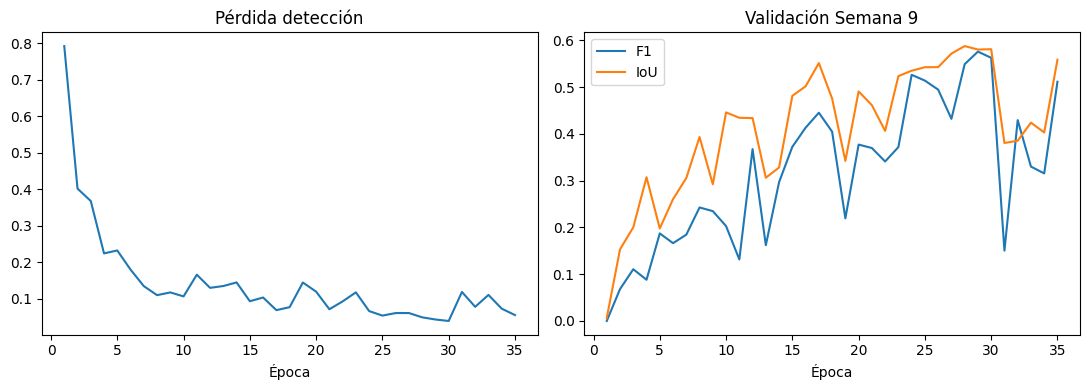

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
hist = json.loads(HISTORIAL.read_text(encoding="utf-8"))
df = pd.DataFrame(hist["historial"])
display(df.tail())
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(df.epoch, df.train_loss); axes[0].set(title="Pérdida detección", xlabel="Época")
axes[1].plot(df.epoch, df.f1, label="F1"); axes[1].plot(df.epoch, df.iou_medio, label="IoU")
axes[1].set(title="Validación Semana 9", xlabel="Época"); axes[1].legend()
plt.tight_layout(); plt.show()

## Salida contractual

No cierres ni muevas el checkpoint. El notebook siguiente usa exactamente la misma ruta según el valor de `MODO_RAPIDO`.